# Loan default model: analysis

This notebook predicts whether a loan applicant will default, compares the model with Bree's
rule-based scorer, and checks fairness across employment groups. Reusable code lives in the
`loan_risk/` package; this notebook runs it and explains the results.

**Contents**
1. Data audit: what's in the data, what's missing, and where it differs from the brief
2. Exploratory analysis: which signals predict default, and how
3. The rule-based baseline: how well it ranks risk, what its decisions cost, and whether it is fair

To re-run: `jupytext --to ipynb analysis.py && jupyter nbconvert --to notebook --execute --inplace analysis.ipynb`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from sklearn.metrics import roc_auc_score
from statsmodels.stats.proportion import proportions_ztest

from loan_risk import plots
from loan_risk.baseline import (
    adjusted_rule_score,
    oracle_default_probability,
    rebuild_rule_score,
    rule_components,
    rule_tiers,
    tiers_from_score,
)
from loan_risk.data import EMPLOYMENT_GROUPS, default_label, load_applications, split_by_outcome
from loan_risk.eda import adversarial_auc, binned_rate, format_rates, rate_table
from loan_risk.evaluation import (
    CONVENTIONS,
    confusion_table,
    convention_metrics,
    matched_tiers,
    paired_bootstrap,
    ranking_metrics,
    save_table,
    tier_table,
)
from loan_risk.fairness import score_conditional_odds
from loan_risk.features import INCOME_VERIFICATION_LABELS, MISMATCH_THRESHOLD, build_features

plots.apply_style()
pd.set_option("display.precision", 3)
GROUP_LABELS = {"employed": "Employed", "self_employed": "Self-employed", "unemployed": "Unemployed"}

applications = load_applications()
resolved, ongoing = split_by_outcome(applications)
y = default_label(resolved)
features = build_features(resolved)
print(f"{len(applications):,} applications: {len(resolved):,} resolved "
      f"({y.sum()} defaults = {y.mean():.1%}), {len(ongoing)} ongoing")

2,000 applications: 1,836 resolved (545 defaults = 29.7%), 164 ongoing


## 1. Data audit

### 1.1 Columns and missing values

Fifteen columns. Only two have gaps, and both gaps have a known cause (sections 1.3 and 1.5).

In [2]:
audit = pd.DataFrame(
    {
        "type": applications.dtypes.astype(str),
        "missing": applications.isna().sum(),
        "first row": applications.iloc[0].astype(str),
    }
)
display(audit)

,type,missing,first row
applicant_id,str,0,APP-0000
stated_monthly_income,float64,0,3683.0
documented_monthly_income,float64,283,3462.0
loan_amount,int64,0,2000
employment_status,str,0,employed
bank_ending_balance,float64,0,3084.0
bank_has_overdrafts,bool,0,False
bank_has_consistent_deposits,bool,0,True
monthly_withdrawals,float64,0,1927.0
monthly_deposits,float64,0,3337.0


### 1.2 What the brief says vs what the data shows

I checked each data characteristic the brief lists against the generated file.

In [3]:
outcome_share = applications["actual_outcome"].value_counts(normalize=True)
doc_ratio = applications["documented_monthly_income"] / applications["stated_monthly_income"]
stated_multiple = 1 / doc_ratio
mismatch = doc_ratio < MISMATCH_THRESHOLD
three_x = int((stated_multiple >= 3).sum())
employment_share = applications["employment_status"].value_counts(normalize=True)
employment_rates = rate_table(y, resolved["employment_status"], EMPLOYMENT_GROUPS)
_, p_self = proportions_ztest(
    employment_rates.loc[["self_employed", "employed"], "defaults"],
    employment_rates.loc[["self_employed", "employed"], "n"],
)

brief_check = pd.DataFrame(
    [
        ("Outcomes: repaid / defaulted / ongoing", "~78% / ~14% / ~8%",
         " / ".join(f"{outcome_share[o]:.1%}" for o in ["repaid", "defaulted", "ongoing"]),
         "No: about twice as many defaults"),
        ("Documented income missing", "~15%",
         f"{applications['documented_monthly_income'].isna().mean():.1%}", "Yes"),
        ("Misrepresentation (stated income 3x+ documented)", "~5% of rows",
         f"{mismatch.sum()} clear mismatches ({mismatch.mean():.1%}); only {three_x} are 3x+",
         f"Partly: a 3x cutoff misses {mismatch.sum() - three_x} of {mismatch.sum()}"),
        ("Employment: employed / self-employed / unemployed", "three values",
         " / ".join(f"{employment_share[g]:.0%}" for g in EMPLOYMENT_GROUPS), "Yes"),
        ("Self-employed default about as often as employed", "roughly the same",
         f"{employment_rates.loc['self_employed', 'rate']:.1%} vs "
         f"{employment_rates.loc['employed', 'rate']:.1%} (p = {p_self:.2f})", "Yes"),
    ],
    columns=["Claim", "Brief", "Data", "Holds?"],
).set_index("Claim")
display(brief_check)

,Brief,Data,Holds?
Claim,,,
Outcomes: repaid / defaulted / ongoing,~78% / ~14% / ~8%,64.5% / 27.3% / 8.2%,No: about twice as many defaults
Documented income missing,~15%,14.1%,Yes
Misrepresentation (stated income 3x+ documented),~5% of rows,85 clear mismatches (4.2%); only 56 are 3x+,Partly: a 3x cutoff misses 29 of 85
Employment: employed / self-employed / unemployed,three values,59% / 31% / 10%,Yes
Self-employed default about as often as employed,roughly the same,29.0% vs 27.2% (p = 0.45),Yes


**Two discrepancies matter for modeling.**
- **The default rate is about double what the brief says**: 27% of all applications, 30% of
  resolved ones. The classes are only mildly imbalanced, so there's no case for resampling.
- **The brief's "3x+" description of misrepresentation is too narrow.** Mismatches are better
  found by the empty gap in documented ÷ stated income (section 2.1); a 3x cutoff would miss a
  third of them.

### 1.3 Missing documented income is structural, not random

In [4]:
display(pd.crosstab(
    applications["num_documents_submitted"],
    applications["documented_monthly_income"].isna().map({True: "missing", False: "present"}),
    margins=True,
))

documented_monthly_income,missing,present,All
num_documents_submitted,,,
0,283,0,283
1,0,683,683
2,0,1034,1034
All,283,1717,2000


Documented income is missing **exactly** when an applicant submitted no documents (283 people).
So the gap is a signal in its own right: these applicants default far more often (section 2.1).
Filling in a typical income (mean or median imputation) would invent a verified income and erase
that signal, so the model gets an explicit "not provided" category instead.

### 1.4 Floors and value sets

In [5]:
at_floor = applications["stated_monthly_income"] == 500
print(f"Stated income at exactly $500 (the generator's floor): {at_floor.sum()} applicants, "
      f"{applications.loc[at_floor, 'employment_status'].eq('unemployed').mean():.0%} of them unemployed")
print(f"Bank balance at exactly $0 (floor): {(applications['bank_ending_balance'] == 0).sum()} applicants")
print(f"Loan amounts take {applications['loan_amount'].nunique()} values: "
      f"{sorted(applications['loan_amount'].unique().tolist())}")

Stated income at exactly $500 (the generator's floor): 41 applicants, 66% of them unemployed
Bank balance at exactly $0 (floor): 176 applicants
Loan amounts take 7 values: [300, 500, 1000, 1500, 2000, 3000, 5000]


Both floors are where the generator clipped values, so the true figure below them is unknown (a
$0 balance may hide an overdrawn account). Tree-based models handle this without special care.
Loan amounts come from a menu of seven sizes, so loan ÷ income varies mostly through income.

### 1.5 `days_to_default` leaks the outcome

In [6]:
defaulted = applications[applications["actual_outcome"] == "defaulted"]
defaulted_features = build_features(defaulted)
print(f"days_to_default is filled in for {applications['days_to_default'].notna().sum()} rows, all of them "
      f"defaults; range {defaulted['days_to_default'].min():.0f}-{defaulted['days_to_default'].max():.0f} days")
candidates = {
    "loan / income": defaulted_features["loan_to_income"],
    "withdrawals / deposits": defaulted_features["withdrawal_to_deposit"],
    "bank balance": defaulted["bank_ending_balance"],
    "rule-based score": defaulted["rule_based_score"],
}
display(pd.DataFrame({
    "Spearman correlation with days_to_default": {
        name: stats.spearmanr(values, defaulted["days_to_default"]).statistic for name, values in candidates.items()
    }
}).round(3))

days_to_default is filled in for 545 rows, all of them defaults; range 15-179 days


,Spearman correlation with days_to_default
loan / income,-0.072
withdrawals / deposits,-0.045
bank balance,-0.003
rule-based score,-0.048


It only exists after a loan has defaulted, so as a feature it would hand the model the answer: it is
excluded. It also shows no pattern (spread evenly over 15-179 days and unrelated to any feature), so
there's nothing to learn about *when* defaults happen. One fact is still useful: **every default
happens by day 179**, which matters for the ongoing loans below.

### 1.6 Ongoing loans look like everyone else

In [7]:
all_features = build_features(applications)
is_ongoing = applications["actual_outcome"].eq("ongoing")
profile = pd.DataFrame(
    {
        "stated monthly income ($)": applications["stated_monthly_income"],
        "loan amount ($)": applications["loan_amount"],
        "loan / income": all_features["loan_to_income"],
        "bank balance ($)": applications["bank_ending_balance"],
        "has overdrafts (share)": applications["bank_has_overdrafts"].astype(float),
        "no income documents (share)": applications["documented_monthly_income"].isna().astype(float),
        "unemployed (share)": all_features["unemployed"].astype(float),
        "rule-based score": applications["rule_based_score"],
    }
)
ongoing_vs_resolved = profile.groupby(is_ongoing.map({False: "resolved", True: "ongoing"})).mean().T[["resolved", "ongoing"]]
ongoing_vs_resolved["p-value (Mann-Whitney)"] = [
    stats.mannwhitneyu(profile.loc[is_ongoing, c], profile.loc[~is_ongoing, c]).pvalue for c in profile.columns
]
display(ongoing_vs_resolved.round(3))
for name, auc in adversarial_auc(all_features, is_ongoing).items():
    print(f"Can {name} tell ongoing loans from resolved ones? Cross-validated AUC = {auc:.2f} (0.5 = chance)")

actual_outcome,resolved,ongoing,p-value (Mann-Whitney)
stated monthly income ($),4439.577,4693.195,0.100
loan amount ($),1554.956,1543.293,0.935
loan / income,0.508,0.415,0.345
bank balance ($),2113.682,2008.866,0.290
has overdrafts (share),0.163,0.213,0.096
no income documents (share),0.141,0.152,0.675
unemployed (share),0.099,0.091,0.752
rule-based score,69.203,69.127,0.844


Can logistic regression tell ongoing loans from resolved ones? Cross-validated AUC = 0.52 (0.5 = chance)
Can gradient boosting tell ongoing loans from resolved ones? Cross-validated AUC = 0.43 (0.5 = chance)


The averages differ a little (for example, 21% vs 16% have overdrafts), but no difference is
statistically significant for a group of 164, and neither classifier can tell the groups apart.
With no real signal, cross-validated AUC scatters around 0.5 and can land below it, as it does for
gradient boosting here. In this dataset "ongoing" was assigned at random, so **leaving these 164
loans out of training introduces no bias here.**

In a real lending book it would. Ongoing loans are the newest ones, and among new loans the fast
defaulters are already labeled while slow outcomes are not. Dropping them over-weights early
defaults and older loans. The production fix is a fixed performance window: label a loan only once
it is 180 days old, since no default here happens after day 179. The alternatives are worse:
calling ongoing loans "repaid" would mislabel the roughly 30% that will default, and a survival
model needs each loan's time on book, which the data doesn't record. The final model scores these
164 loans at the end.

## 2. Exploratory analysis

### 2.1 Income verification: a clean gap, and the strongest single signal

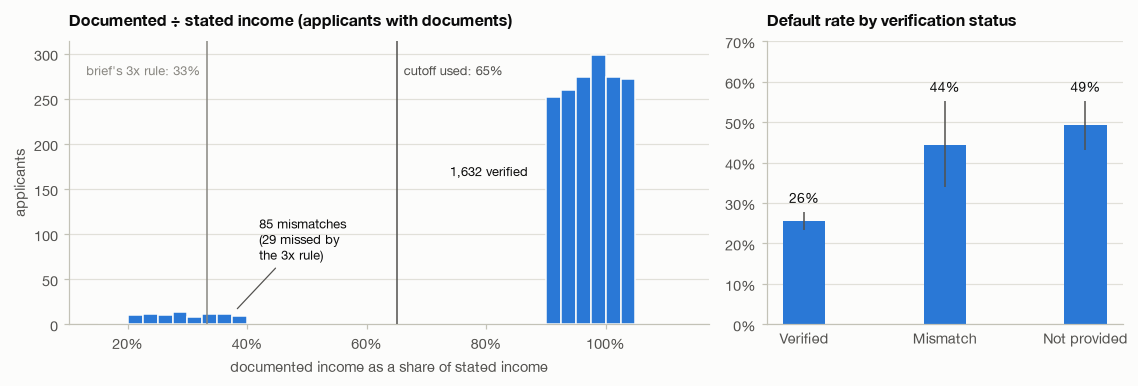

,n,defaults,rate (%),ci_low (%),ci_high (%)
verified,1499,383,25.6,23.4,27.8
mismatch,79,35,44.3,33.9,55.3
not provided,258,127,49.2,43.2,55.3


In [8]:
ratio = doc_ratio.dropna()
status = features["income_verification"].map(INCOME_VERIFICATION_LABELS)
verification_rates = rate_table(y, status, ["verified", "mismatch", "not provided"])
n_mismatch = int((ratio < MISMATCH_THRESHOLD).sum())
missed_by_3x = int(((ratio > 1 / 3) & (ratio < MISMATCH_THRESHOLD)).sum())

fig, (ax_hist, ax_rate) = plt.subplots(1, 2, figsize=(10.5, 3.6), gridspec_kw={"width_ratios": [1.8, 1]})
counts, _, _ = ax_hist.hist(ratio, bins=np.arange(0.15, 1.1251, 0.025), color=plots.BLUE,
                            edgecolor=plots.SURFACE, linewidth=1, zorder=2)
top = counts.max()
ax_hist.axvline(MISMATCH_THRESHOLD, color=plots.INK_SECONDARY, linewidth=1, zorder=3)
ax_hist.axvline(1 / 3, color=plots.MUTED, linewidth=1, zorder=3)
ax_hist.text(MISMATCH_THRESHOLD + 0.012, top * 0.97, "cutoff used: 65%", color=plots.INK_SECONDARY,
             fontsize=8.5, va="top")
ax_hist.text(1 / 3 - 0.012, top * 0.97, "brief's 3x rule: 33%", color=plots.MUTED, fontsize=8.5,
             va="top", ha="right")
ax_hist.annotate(f"{n_mismatch} mismatches\n({missed_by_3x} missed by\nthe 3x rule)", xy=(0.38, top * 0.05),
                 xytext=(0.42, top * 0.24), fontsize=8.5, color=plots.INK, ha="left",
                 arrowprops={"arrowstyle": "-", "color": plots.INK_SECONDARY, "linewidth": 0.8})
ax_hist.text(0.87, top * 0.55, f"{len(ratio) - n_mismatch:,} verified", ha="right", fontsize=8.5, color=plots.INK)
ax_hist.set_title("Documented ÷ stated income (applicants with documents)")
ax_hist.set_xlabel("documented income as a share of stated income")
ax_hist.set_ylabel("applicants")
plots.percent_axis(ax_hist, "x")
plots.rate_bars(ax_rate, verification_rates, labels=["Verified", "Mismatch", "Not provided"])
ax_rate.set_title("Default rate by verification status")
ax_rate.set_ylim(0, 0.7)
fig.tight_layout()
plots.save(fig, "fig1_income_verification")
plt.show()
display(format_rates(verification_rates))

Documented income either matches stated income (90-105%) or falls far below it (21-40%), with
nothing in between. So any cutoff inside the gap gives the same split; I use 65%. The brief's "3x"
description would miss the 29 mismatches between 33% and 40%.

Applicants whose income can't be verified default far more often: 44% with a mismatch and 49% with
no documents, against 26% when income is verified. The two failure modes behave alike, which is why
they share one feature with three levels rather than an imputed income.

### 2.2 Risk jumps in steps

Each panel splits applicants into ten equal-sized groups by one feature (no hand-picked cutoffs) and
shows each group's default rate. The shaded band is the 95% confidence interval; the gray line is
the overall default rate.

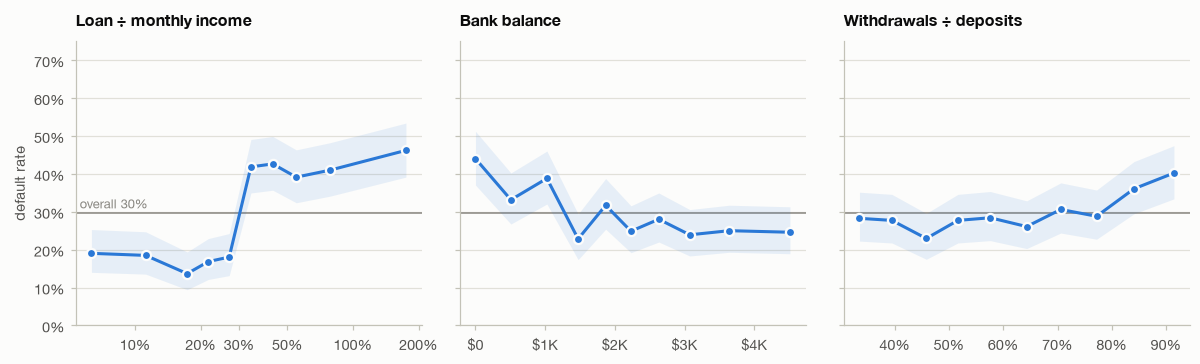

x_low    x_high    n  rate (%)  ci_low (%)  \
Loan ÷ monthly income  0     0.035     0.083  184      19.0        14.0   
                       1     0.083     0.146  184      18.5        13.5   
                       2     0.146     0.194  183      13.7         9.4   
                       3     0.194     0.241  184      16.8        12.1   
                       4     0.241     0.299  183      18.0        13.1   
                       5     0.300     0.379  184      41.8        35.0   
                       6     0.379     0.474  183      42.6        35.7   
                       7     0.475     0.645  184      39.1        32.4   
                       8     0.646     1.003  183      41.0        34.1   
                       9     1.003    10.000  184      46.2        39.1   
Bank balance           0     0.000   144.000  184      44.0        37.0   
                       1   147.000   775.000  184      33.2        26.8   
                       2   776.000  1234.000  183      38.8        32.0   
                       3  1239.000  1677.000  184      22.8        17.4   
                       4  1679.000  2052.000  183      31.7        25.4   
                       5  2054.000  2416.000  185      24.9        19.2   
                       6  2417.000  2866.000  182      28.0        22.0   
                       7  2869.000  3341.000  184      23.9        18.3   
                       8  3348.000  4038.000  184      25.0        19.3   
                       9  4040.000  8719.000  183      24.6        18.9   
Withdrawals ÷ deposits 0     0.300     0.366  184      28.3        22.3   
                       1     0.367     0.429  184      27.7        21.8   
                       2     0.429     0.487  183      23.0        17.5   
                       3     0.489     0.545  184      27.7        21.8   
                       4     0.545     0.609  183      28.4        22.4   
                       5     0.610     0.677  184      26.1        20.3   
                       6     0.677     0.734  183      30.6        24.4   
                       7     0.734     0.807  184      28.8        22.7   
                       8     0.808     0.877  183      36.1        29.5   
                       9     0.878     0.950  184      40.2        33.4   

                          ci_high (%)  
Loan ÷ monthly income  0         25.3  
                       1         24.7  
                       2         19.4  
                       3         22.9  
                       4         24.2  
                       5         49.1  
                       6         49.9  
                       7         46.3  
                       8         48.2  
                       9         53.4  
Bank balance           0         51.2  
                       1         40.2  
                       2         46.0  
                       3         29.4  
                       4         38.8  
                       5         31.6  
                       6         34.9  
                       7         30.6  
                       8         31.7  
                       9         31.3  
Withdrawals ÷ deposits 0         35.2  
                       1         34.6  
                       2         29.6  
                       3         34.6  
                       4         35.3  
                       5         32.9  
                       6         37.6  
                       7         35.7  
                       8         43.2  
                       9         47.4

In [9]:
drivers = {
    "loan_to_income": "Loan ÷ monthly income",
    "bank_ending_balance": "Bank balance",
    "withdrawal_to_deposit": "Withdrawals ÷ deposits",
}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
binned = {}
for ax, (column, title) in zip(axes, drivers.items()):
    table = binned_rate(features[column], y, n_bins=10)
    binned[title] = table
    ax.axhline(y.mean(), color=plots.MUTED, linewidth=1, zorder=1)
    plots.rate_line(ax, table)
    ax.set_title(title)
axes[0].set_xscale("log")
axes[0].set_xticks([0.1, 0.2, 0.3, 0.5, 1, 2], ["10%", "20%", "30%", "50%", "100%", "200%"])
axes[0].minorticks_off()
plots.dollar_axis(axes[1])
plots.percent_axis(axes[2], "x")
axes[0].set_ylabel("default rate")
axes[0].set_ylim(0, 0.75)
axes[0].text(axes[0].get_xlim()[0], y.mean() + 0.012, f" overall {y.mean():.0%}", color=plots.MUTED, fontsize=8.5)
fig.tight_layout()
plots.save(fig, "fig2_risk_steps")
plt.show()
display(pd.concat({
    title: format_rates(table[["x_low", "x_high", "n", "rate", "ci_low", "ci_high"]]) for title, table in binned.items()
}).round(3))

- **Loan ÷ income** has a sharp step: 14-19% default below 30% of monthly income, 39-46% above it,
  and little change after that.
- **Bank balance** matters mostly at the low end: 44% default in the lowest tenth (under about $150)
  and 33-39% up to about $1,200, against roughly 25% above. This pattern is noisier.
- **Withdrawals ÷ deposits** is flat until about 80%, then rises to 36-40%.

A straight-line (linear) term gets step shapes like these wrong. Tree-based models learn them
directly from the data, without anyone choosing the cutoffs by hand.

### 2.3 Yes/no signals, and two columns that carry no signal

In [10]:
def yes_no(series: pd.Series) -> pd.Series:
    return series.map({True: "yes", False: "no"})


binary_rates = pd.concat({
    "Has overdrafts": rate_table(y, yes_no(resolved["bank_has_overdrafts"]), ["no", "yes"]),
    "Documents submitted": rate_table(y, resolved["num_documents_submitted"].astype(str), ["0", "1", "2"]),
    "Consistent deposits": rate_table(y, yes_no(resolved["bank_has_consistent_deposits"]), ["no", "yes"]),
})
display(format_rates(binary_rates))

with_label = resolved.assign(defaulted=y)
consistent = with_label["bank_has_consistent_deposits"]
proxy = pd.DataFrame({
    "share with consistent deposits": with_label.groupby("employment_status")["bank_has_consistent_deposits"].mean(),
    "default rate if consistent": with_label[consistent].groupby("employment_status")["defaulted"].mean(),
    "default rate if not": with_label[~consistent].groupby("employment_status")["defaulted"].mean(),
}).reindex(EMPLOYMENT_GROUPS)
display((100 * proxy).round(1).rename(index=GROUP_LABELS).add_suffix(" (%)"))

n  defaults  rate (%)  ci_low (%)  ci_high (%)
Has overdrafts      no   1537       400      26.0        23.9         28.3
                    yes   299       145      48.5        42.9         54.1
Documents submitted 0     258       127      49.2        43.2         55.3
                    1     637       159      25.0        21.8         28.5
                    2     941       259      27.5        24.8         30.5
Consistent deposits no    642       194      30.2        26.8         33.9
                    yes  1194       351      29.4        26.9         32.0

,share with consistent deposits (%),default rate if consistent (%),default rate if not (%)
employment_status,,,
Employed,82.2,28.3,22.2
Self-employed,41.5,28.5,29.3
Unemployed,35.7,47.7,46.2


**Overdrafts** nearly double the default rate (26% to 49%). Two columns carry no signal:
- **Number of documents** matters only as zero versus any: one and two documents default at 25%
  and 28%.
- **Deposit consistency** makes no meaningful difference, overall (30% vs 29%) or within any
  employment group. Yet it tracks employment closely: 82% of employed applicants have consistent
  deposits, against 42% of self-employed and 36% of unemployed. A model using it would learn
  nothing about risk but could penalize self-employment indirectly, so it is left out and
  revisited in the fairness analysis.

### 2.4 Employment: similar risk, very different treatment

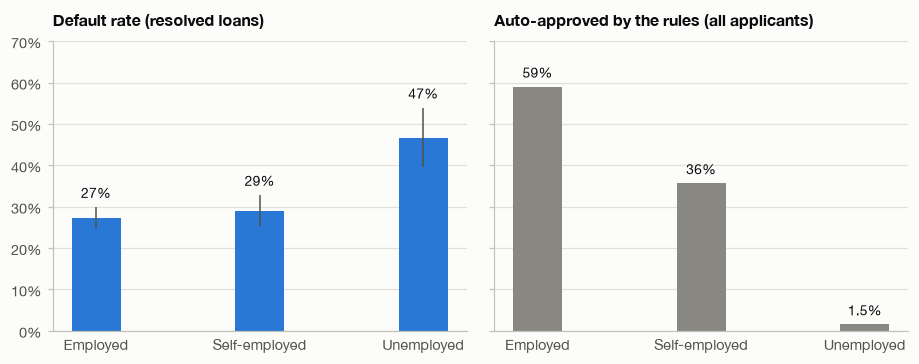

,n,defaults,rate (%),ci_low (%),ci_high (%),rules: approved (%),rules: denied (%),rules: flagged_for_review (%)
Employed,1088,296,27.2,24.6,29.9,59.0,6.8,34.2
Self-employed,566,164,29.0,25.4,32.8,35.6,16.9,47.4
Unemployed,182,85,46.7,39.6,53.9,1.5,46.7,51.8


Approval ratio, self-employed vs employed: 0.60 (below 0.8 is the usual warning line)


In [11]:
decision_mix = pd.crosstab(
    applications["employment_status"], applications["rule_based_decision"], normalize="index"
).reindex(EMPLOYMENT_GROUPS)
labels = [GROUP_LABELS[g] for g in EMPLOYMENT_GROUPS]
fig, (ax_default, ax_approve) = plt.subplots(1, 2, figsize=(8.5, 3.4), sharey=True)
plots.rate_bars(ax_default, employment_rates, labels)
ax_default.set_title("Default rate (resolved loans)")
plots.rate_bars(ax_approve, decision_mix[["approved"]].rename(columns={"approved": "rate"}), labels,
                color=plots.RULES_COLOR)
ax_approve.set_title("Auto-approved by the rules (all applicants)")
ax_default.set_ylim(0, 0.7)
fig.tight_layout()
plots.save(fig, "fig3_employment")
plt.show()

summary = format_rates(employment_rates).join((100 * decision_mix).round(1).add_prefix("rules: ").add_suffix(" (%)"))
display(summary.rename(index=GROUP_LABELS))
ratio_self = decision_mix.loc["self_employed", "approved"] / decision_mix.loc["employed", "approved"]
print(f"Approval ratio, self-employed vs employed: {ratio_self:.2f} (below 0.8 is the usual warning line)")

Self-employed applicants default about as often as employed ones (29% vs 27%; not a significant
difference, p = 0.45). Yet the rules auto-approve them far less often: 36% vs 59%, an approval
ratio of 0.60, well below the 0.8 warning line used in fair-lending checks. Unemployed applicants
really are riskier (47%) and are almost never auto-approved (1.5%). Whether the rule score actually
mis-prices these groups, once the other risk factors are accounted for, is tested when the
baseline is evaluated.

### 2.5 What this means for the model

- **Label and exclusions.** Predict defaulted (1) vs repaid (0) on the 1,836 resolved loans. Leave out
  `days_to_default` (it leaks the outcome), the rule-based score and decision (outputs of the system
  being replaced) and `applicant_id`.
- **Missing documents and mismatches become one feature**, `income_verification` (verified /
  mismatch / not provided), instead of an imputed income.
- **Use a model that can learn steps.** Risk jumps at thresholds (section 2.2), so a straight-line
  effect would mis-fit; trees find the thresholds in the data.
- **Drop columns with no signal**: deposit consistency (also an employment proxy) and the document
  count beyond zero.
- **No resampling.** A 30% default rate is only mildly imbalanced, and resampling would distort the
  predicted probabilities. Decision thresholds handle the business costs instead.

## 3. The rule-based baseline

The rules combine five factors into a 0-100 score, then approve at 75 or above, flag for human
review at 50-74 and deny below 50. This section measures how well that works and where it goes
wrong. The rules need no training, so they are evaluated on all 1,836 resolved loans.

### 3.1 How the score really behaves

In [12]:
rebuilt = rebuild_rule_score(applications)
gap = (rebuilt - applications["rule_based_score"]).abs().round(2)
print(f"Rebuilt rubric: same decision for {(tiers_from_score(rebuilt) == rule_tiers(applications)).sum():,} of "
      f"{len(applications):,} applicants. Score identical for {(gap == 0).sum():,}, 0.1 apart for {(gap == 0.1).sum()}, "
      f"further apart for {(gap > 0.1).sum()} (all from rounding in the CSV)")
components = rule_components(applications)
print("Income-verification points awarded:", components["income_verification"].value_counts().to_dict())
no_docs = applications["documented_monthly_income"].isna()
print(f"Highest score of any applicant without documents: {applications.loc[no_docs, 'rule_based_score'].max():.1f} "
      "(auto-approval needs 75)")

Rebuilt rubric: same decision for 2,000 of 2,000 applicants. Score identical for 1,979, 0.1 apart for 20, further apart for 1 (all from rounding in the CSV)
Income-verification points awarded: {95: 1631, 0: 368, 40: 1}
Highest score of any applicant without documents: 64.5 (auto-approval needs 75)


Rebuilding the rubric from the CSV reproduces all 2,000 decisions, so the baseline is understood
exactly. Two quirks stand out:
- **Income verification is effectively all-or-nothing**: 95 points when documents match, 0
  otherwise. The 40-point "partial match" branch fires for one applicant, and only because the CSV
  rounds documented income.
- **Applicants without documents can never be auto-approved**: missing those 28.5 weighted points
  caps their score at 64.5. That fits the data (they default at 49%), but it comes from the weights
  rather than from an explicit policy.

### 3.2 How well the rules rank risk

In [13]:
rule_risk = -resolved["rule_based_score"].to_numpy()
oracle_p = oracle_default_probability(resolved)
ranking = pd.DataFrame.from_dict(
    {
        "Rule-based score": ranking_metrics(y, rule_risk),
        "Oracle: true default probability (diagnostic only)": ranking_metrics(y, oracle_p),
    },
    orient="index",
)
display(ranking.round(3))
save_table(ranking, "baseline_ranking")
no_risk_factors = oracle_p == oracle_p.min()
print(f"Most any model could add over the rules: {ranking['ROC-AUC'].iloc[1] - ranking['ROC-AUC'].iloc[0]:.3f} AUC")
print(f"Applicants with none of the generator's risk factors: {no_risk_factors.sum()}, "
      f"and {y[no_risk_factors].mean():.0%} of them still default")

,ROC-AUC,PR-AUC
Rule-based score,0.706,0.502
Oracle: true default probability (diagnostic only),0.741,0.525


Most any model could add over the rules: 0.035 AUC
Applicants with none of the generator's risk factors: 459, and 9% of them still default


**AUC** is the probability that a randomly chosen defaulter gets a riskier score than a randomly
chosen repayer: 0.5 is a coin flip, 1.0 is perfect. **PR-AUC** (average precision) measures how
cleanly the riskiest scores pick out defaulters; a random score gets about 0.30 here, the default
rate. The rules reach **0.706 AUC**.

Because the brief includes the generator, I can compute each applicant's true default probability:
the "oracle". It is never used to train, tune or select anything; it only shows the ceiling, **0.741
AUC**. Outcomes are noisy by design: 459 applicants with none of the risk factors still default 9% of
the time. So **the most any model can add over the rules is about 0.035 AUC**, and models should be
judged against that ceiling rather than a perfect 1.0.

### 3.3 What the decisions cost

In [14]:
rule_decisions = rule_tiers(resolved)
decision_table = tier_table(y, rule_decisions)
display(decision_table.round(3))
rule_metrics = convention_metrics(y, rule_decisions)
display(rule_metrics.round(3))
for name, flagged in CONVENTIONS.items():
    print(f"Confusion matrix, convention {name}")
    display(confusion_table(y, np.isin(rule_decisions, flagged)))
save_table(decision_table, "baseline_tiers")
save_table(rule_metrics, "baseline_conventions")

,applicants,share of applicants,repaid,defaulted,default rate
approve,851,0.464,710,141,0.166
review,720,0.392,459,261,0.362
deny,265,0.144,122,143,0.540


,TP,FP,FN,TN,precision,recall,F1,FPR,FNR
A: only deny = predicted default,143,122,402,1169,0.54,0.262,0.353,0.095,0.738
B: not auto-approved = predicted default,404,581,141,710,0.41,0.741,0.528,0.450,0.259


Confusion matrix, convention A: only deny = predicted default


,predicted repay,predicted default
actual,,
repaid,1169,122
defaulted,402,143


Confusion matrix, convention B: not auto-approved = predicted default


,predicted repay,predicted default
actual,,
repaid,710,581
defaulted,141,404


- Auto-approved applicants default at 17% and denied ones at 54%. The **review tier holds 39% of
  applicants with a 36% default rate, close to the 30% average**: the rules hand their hardest cases
  to people.
- Precision, recall, F1 and error rates need a yes/no prediction, but reviewers' decisions on
  flagged applications aren't in the data. So I report two conventions that bracket the truth:
  - **A** counts only "deny" as predicting default, as if reviewers approved every flagged case. Its
    false-positive rate is the share of good applicants wrongly denied: **9.5%**. But 74% of
    defaults are not denied.
  - **B** counts anything not auto-approved as predicting default, as if reviewers denied every
    flagged case. Its false-negative rate is the share of defaults that slip through
    auto-approval: **26%**. But 45% of good applicants are held back.
- The model is compared under both conventions later.

### 3.4 Does the score mis-price employment groups?

A fair score means the same risk for everyone with the same score. The test fits
logit(default) ~ score + employment group. If group still predicts default once the score is known,
the score mis-prices that group. An odds ratio below 1 means the group defaults less often than its
score implies, so the score over-states its risk.

,odds ratio,ci_low,ci_high,p-value
Self-employed,0.667,0.519,0.857,0.002
Unemployed,0.754,0.521,1.090,0.133


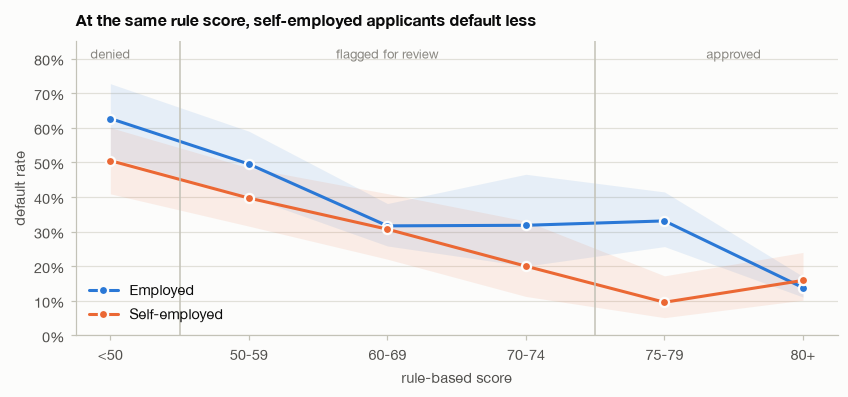

Employed                                 Self-employed           \
             n rate (%) ci_low (%) ci_high (%)             n rate (%)   
<50         75     62.7       51.4        72.7           101     50.5   
50-59      103     49.5       40.1        59.0           126     39.7   
60-69      218     31.7       25.8        38.1            88     30.7   
70-74       44     31.8       20.0        46.6            50     20.0   
75-79      133     33.1       25.7        41.5            94      9.6   
80+        515     13.8       11.1        17.0           107     15.9   

                              
      ci_low (%) ci_high (%)  
<50         40.9        60.0  
50-59       31.6        48.4  
60-69       22.0        41.0  
70-74       11.2        33.0  
75-79        5.1        17.2  
80+         10.2        24.0

In [15]:
score_bias = score_conditional_odds(
    y, resolved["rule_based_score"] / 10, resolved["employment_status"], order=EMPLOYMENT_GROUPS
)
display(score_bias.rename(index=GROUP_LABELS).round(3))
save_table(score_bias, "baseline_score_bias")

band_labels = ["<50", "50-59", "60-69", "70-74", "75-79", "80+"]
bands = pd.cut(resolved["rule_based_score"], [0, 50, 60, 70, 75, 80, 101], right=False,
               labels=band_labels).astype(str).to_numpy()
fig, ax = plt.subplots(figsize=(7.8, 3.7))
x = np.arange(len(band_labels))
band_rates = {}
for group, color in [("employed", plots.BLUE), ("self_employed", plots.ORANGE)]:
    in_group = resolved["employment_status"].eq(group).to_numpy()
    table = rate_table(y[in_group], bands[in_group], band_labels)
    band_rates[GROUP_LABELS[group]] = table
    ax.fill_between(x, table["ci_low"], table["ci_high"], color=color, alpha=0.10, linewidth=0)
    ax.plot(x, table["rate"], color=color, marker="o", markersize=6, markeredgecolor=plots.SURFACE,
            markeredgewidth=1.5, label=GROUP_LABELS[group])
for boundary in (0.5, 3.5):
    ax.axvline(boundary, color=plots.AXIS, linewidth=1)
for center, zone in [(0, "denied"), (2, "flagged for review"), (4.5, "approved")]:
    ax.text(center, 0.80, zone, ha="center", color=plots.MUTED, fontsize=8.5)
ax.set_xticks(x, band_labels)
ax.set_xlabel("rule-based score")
ax.set_ylabel("default rate")
ax.set_ylim(0, 0.85)
plots.percent_axis(ax)
ax.legend(loc="lower left")
ax.set_title("At the same rule score, self-employed applicants default less")
fig.tight_layout()
plots.save(fig, "fig4_rule_score_bias")
plt.show()
display(pd.concat({g: format_rates(t[["n", "rate", "ci_low", "ci_high"]]) for g, t in band_rates.items()}, axis=1))

In [16]:
score = resolved["rule_based_score"]
self_marginal = (resolved["employment_status"].eq("self_employed") & score.between(69, 74.95)).to_numpy()
employed_marginal = (resolved["employment_status"].eq("employed") & score.between(75, 80.95)).to_numpy()
counts_2x2 = [[y[m].sum(), (1 - y[m]).sum()] for m in (self_marginal, employed_marginal)]
print(f"Self-employed scoring 69-74.9 (approved if their 6-point penalty were removed): "
      f"{y[self_marginal].mean():.0%} default (n = {self_marginal.sum()})")
print(f"Employed scoring 75-80.9 (approved today): {y[employed_marginal].mean():.0%} default "
      f"(n = {employed_marginal.sum()}); Fisher exact test p = {stats.fisher_exact(counts_2x2).pvalue:.2f}")
partial_credit = rule_components(resolved)["income_level"].eq(45).to_numpy()
employed_75 = (resolved["employment_status"].eq("employed") & score.between(75, 79.95)).to_numpy()
print(f"Employed applicants scoring 75-79.9: {employed_75.sum()}. {partial_credit[employed_75].mean():.0%} of them "
      f"got partial credit for income only 2-3x the loan; those default at {y[employed_75 & partial_credit].mean():.0%}")

Self-employed scoring 69-74.9 (approved if their 6-point penalty were removed): 23% default (n = 60)
Employed scoring 75-80.9 (approved today): 34% default (n = 166); Fisher exact test p = 0.15
Employed applicants scoring 75-79.9: 133. 71% of them got partial credit for income only 2-3x the loan; those default at 35%


**The score over-states self-employed applicants' risk.** At the same score they are about a third
less likely to default (odds ratio 0.67, 95% CI 0.52-0.86, p = 0.002). The chart shows it band by
band, most starkly at 75-79, where employed applicants default at 33% and self-employed ones at 10%.
This is the 6-point penalty at work (weight 0.15 times the 40-point gap): self-employed applicants
need better finances than employed ones to reach the same score. Unemployed applicants also do a
little better than their score implies (odds ratio 0.75), but that isn't statistically significant
(p = 0.13).

Two supporting observations:
- **Near the cutoff:** self-employed applicants who would be approved without the penalty (scores
  69-74.9) default at 23%, while employed applicants approved today with 75-80.9 default at 34%.
  That points the same way but isn't significant on its own (p = 0.15), so the score-conditional
  test above is the real evidence.
- **A second rubric flaw:** employed applicants scoring 75-79 default at 33%, no less than those at
  70-74. Most of them (71%) only reach the approval band through partial credit for income just 2-3x
  the loan, and section 2.2 showed loans that large relative to income are already high-risk.

### 3.5 Can a simple patch to the rules fix this?

Before building a model, it's worth asking how far a small change to the rubric gets. Each patch is
applied exactly to the original score:
- **Patch 1:** score self-employed applicants like employed ones (+6 points).
- **Patch 2:** also stop rewarding deposit consistency (everyone gets those points), since it tracks
  employment but doesn't predict default (section 2.3).

For a fair comparison of ranking quality, every version approves as many applicants as today's rules
(851) and denies as many (265). The oracle row shows the best possible result at those volumes.

In [17]:
n_approve, n_deny = int((rule_decisions == "approve").sum()), int((rule_decisions == "deny").sum())
group_mask = {g: resolved["employment_status"].eq(g).to_numpy() for g in EMPLOYMENT_GROUPS}


def approval_ratio(tiers: np.ndarray, group: str) -> float:
    return (tiers[group_mask[group]] == "approve").mean() / (tiers[group_mask["employed"]] == "approve").mean()


rule_versions = {
    "Rules as they are": rule_risk,
    "Patch 1: self-employed scored like employed": -adjusted_rule_score(resolved, self_employed_points=100).to_numpy(),
    "Patch 2: ...and deposit consistency ignored": -adjusted_rule_score(
        resolved, self_employed_points=100, ignore_deposit_consistency=True).to_numpy(),
    "Oracle (ceiling, diagnostic only)": oracle_p,
}
rows = {}
for name, risk in rule_versions.items():
    same_volume = matched_tiers(risk, n_approve, n_deny)
    gain = paired_bootstrap(y, rule_risk, risk, roc_auc_score)
    rows[name] = {
        "ROC-AUC": roc_auc_score(y, risk),
        "AUC gain [95% CI]": f"{gain['difference']:+.3f} [{gain['ci_low']:+.3f}, {gain['ci_high']:+.3f}]",
        "defaults auto-approved": int(y[same_volume == "approve"].sum()),
        "defaults denied": int(y[same_volume == "deny"].sum()),
        "good applicants denied": int((1 - y)[same_volume == "deny"].sum()),
        "self-employed approval ratio": approval_ratio(same_volume, "self_employed"),
        "unemployed approval ratio": approval_ratio(same_volume, "unemployed"),
    }
rule_patches = pd.DataFrame.from_dict(rows, orient="index")
display(rule_patches.round(3))
save_table(rule_patches, "baseline_patches")

,ROC-AUC,AUC gain [95% CI],defaults auto-approved,defaults denied,good applicants denied,self-employed approval ratio,unemployed approval ratio
Rules as they are,0.706,"+0.000 [+0.000, +0.000]",141,143,122,0.596,0.018
Patch 1: self-employed scored like employed,0.711,"+0.005 [-0.000, +0.010]",129,145,120,0.793,0.020
Patch 2: ...and deposit consistency ignored,0.718,"+0.011 [+0.003, +0.019]",124,155,110,0.878,0.062
"Oracle (ceiling, diagnostic only)",0.741,"+0.035 [+0.019, +0.052]",123,170,95,0.929,0.105


- **Patch 1** lifts the self-employed approval ratio from 0.60 to 0.79 and improves ranking slightly
  (AUC 0.711; the confidence interval just touches zero). At the same volume it lets through fewer
  defaults (129 vs 141), because the self-employed applicants it promotes are safer than their old
  score said.
- **Patch 2** goes further: AUC 0.718 (a clear gain of +0.011, 95% CI +0.003 to +0.019), 124
  defaults auto-approved, 155 caught in the deny tier, 110 good applicants denied instead of 122,
  and a self-employed approval ratio of 0.88. Removing a factor that only measured employment made
  the rules both fairer and more accurate.
- **Patch 2 is the real baseline to beat.** It is a two-line change a rules team could ship
  tomorrow, and it captures about a third of the achievable AUC gain (0.706 to 0.718, against a
  0.741 ceiling). At the approval cutoff it is already close to the ceiling (124 defaults vs 123).
  What patches don't fix is the rest of the rubric: partial credit for income only 2-3x the loan,
  overdrafts carrying 6 of 100 points despite nearly doubling the default rate, and a withdrawals
  factor that rises in a straight line when the data shows a step near 80%. Re-tuning those by hand
  is what a model does systematically, and the next sections test whether that is worth it.